# Freight Rate Prediction — Spotter AI Assessment

**Candidate:** Md Rakibul Islam

## Objective
Train and validate a regression model for freight-rate prediction, generate predictions for the 12,000 validation loads, and estimate rates for the 31 December 2025 chart inputs.

## Workflow
1. Load the supplied datasets and inspect data quality.
2. Use a time-based validation split (January–September for training; October for validation).
3. Engineer date and route features and compare regression models.
4. Fit the final CatBoost model on all labeled development data.
5. Generate `validation_predictions.csv` and `data/december_chart_inputs.csv`.
6. If `score.py` is present, run the assessment scorer.

> **Data requirement:** Place the assessment files in the notebook environment. This notebook supports the standard `data/` folder layout and the flat `/content/` filenames used during development. Keep the supplied assessment data private and follow Spotter's submission instructions.

train-test.csv ---------------------(#1)
      

Explore + clean + engineer features (#2)
      

Choose validation strategy -------- (#3)
      

Train ML regression model ----------(#4)
      

Validate model ---------------------(#5)
      

Retrain using development data -----(#6)
      

Predict validation.csv (12,000 loads)(#7)
      

validation_predictions.csv ----------(#8)

december-chart-inputs.csv ------(#9)
      
Same trained model -------------(#10)
      
31 predictions for December 2025(#11)
      
score.py -----------------------(#12)
      
candidate_december.png ---------(#13)

In [41]:
!pip install -q catboost pandas numpy scikit-learn matplotlib
!pip install -q xgboost


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import time

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from xgboost import XGBRegressor
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import mean_absolute_error, mean_squared_error
from catboost import CatBoostRegressor

import re
import nltk
from nltk.corpus import stopwords

In [43]:
train = pd.read_csv(f"/content/train-test.csv")
validation = pd.read_csv(f"/content/validation.csv")
december = pd.read_csv(f"/content/december-chart-inputs.csv")


In [44]:
train.shape

(48000, 14)

In [45]:
validation.shape

(12000, 13)

In [46]:
december.shape

(31, 7)

In [47]:
train.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [48]:
train.columns.tolist()

['load_id',
 'pickup',
 'delivery',
 'pickup_lat',
 'pickup_lon',
 'delivery_lat',
 'delivery_lon',
 'distance',
 'equipment',
 'weight',
 'date',
 'market_index',
 'quote_signal',
 'posted_rate']

In [49]:
validation.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541


In [50]:
december.head()

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,NaN
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,NaN


In [51]:
print("Missing values:")
print(train.isna().sum())

print("\nDuplicate rows:", train.duplicated().sum())
print("Duplicate load IDs:", train["load_id"].duplicated().sum())

print("\nData types:")
print(train.dtypes)

Missing values:
load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

Duplicate rows: 0
Duplicate load IDs: 0

Data types:
load_id          object
pickup           object
delivery         object
pickup_lat      float64
pickup_lon      float64
delivery_lat    float64
delivery_lon    float64
distance        float64
equipment        object
weight          float64
date             object
market_index    float64
quote_signal    float64
posted_rate     float64
dtype: object


In [52]:
train["date"] = pd.to_datetime(train["date"])
validation["date"] = pd.to_datetime(validation["date"])
december["date"] = pd.to_datetime(december["date"])

print("Training period:")
print(train["date"].min(), "to", train["date"].max())

print("\nValidation period:")
print(validation["date"].min(), "to", validation["date"].max())

Training period:
2025-01-01 00:00:00 to 2025-10-31 00:00:00

Validation period:
2025-11-01 00:00:00 to 2025-12-31 00:00:00


In [53]:
train["posted_rate"].describe()

,posted_rate
count,48000.000000
mean,2373.980682
std,1486.493245
min,57.220000
25%,1251.555000
50%,2030.760000
75%,3330.750000
max,25533.000000


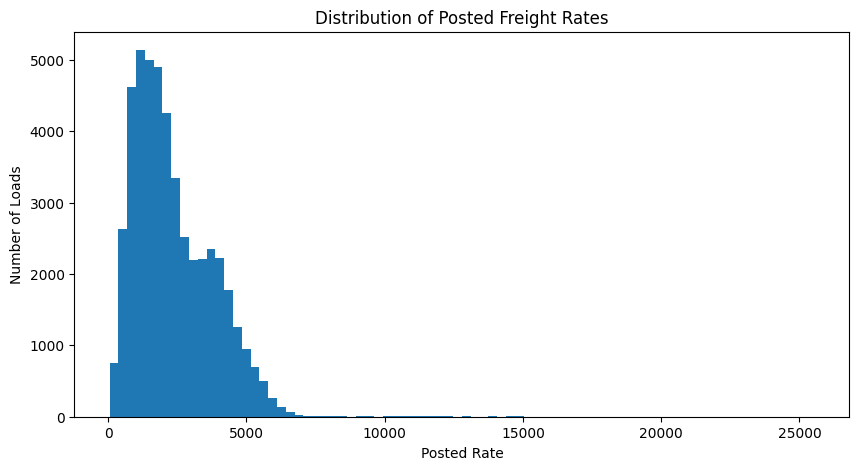

In [54]:
plt.figure(figsize=(10, 5))
plt.hist(train["posted_rate"], bins=80)
plt.xlabel("Posted Rate")
plt.ylabel("Number of Loads")
plt.title("Distribution of Posted Freight Rates")
plt.show()

In [55]:
numeric_cols = [
    "distance",
    "weight",
    "market_index",
    "quote_signal",
    "posted_rate"
]

print(train[numeric_cols].corr()["posted_rate"].sort_values(ascending=False))

posted_rate     1.000000
distance        0.908519
weight          0.034840
market_index    0.034165
quote_signal   -0.039858
Name: posted_rate, dtype: float64


# Feature engineering

In [56]:
def make_features(df, city_coords=None):
    x = df.copy()

    x["date"] = pd.to_datetime(x["date"])

    # If coordinates are not supplied, derive them from city names.
    if "pickup_lat" not in x.columns and city_coords is not None:

        pickup_lat = {
            city: float(coords["lat"])
            for city, coords in city_coords.items()
        }

        pickup_lon = {
            city: float(coords["lon"])
            for city, coords in city_coords.items()
        }

        x["pickup_lat"] = x["pickup"].map(pickup_lat)
        x["pickup_lon"] = x["pickup"].map(pickup_lon)

        x["delivery_lat"] = x["delivery"].map(pickup_lat)
        x["delivery_lon"] = x["delivery"].map(pickup_lon)

#date features
    x["year"] = x["date"].dt.year
    x["month"] = x["date"].dt.month
    x["day"] = x["date"].dt.day
    x["dayofweek"] = x["date"].dt.dayofweek
    x["dayofyear"] = x["date"].dt.dayofyear

    # Continuous time index
    x["time_index"] = (
        x["date"] - pd.Timestamp("2025-01-01")
    ).dt.days

    # Route
    x["route"] = (
        x["pickup"].astype(str)
        + "__"
        + x["delivery"].astype(str)
    )

    # Weight-adjusted distance
    x["distance_per_1000lb"] = (
        x["distance"] /
        (x["weight"] / 1000).replace(0, np.nan)
    )

    features = [
        "pickup",
        "delivery",
        "pickup_lat",
        "pickup_lon",
        "delivery_lat",
        "delivery_lon",
        "distance",
        "equipment",
        "weight",
        "year",
        "month",
        "day",
        "dayofweek",
        "dayofyear",
        "time_index",
        "route",
        "distance_per_1000lb"
    ]

    return x[features]

# Build a city-coordinate lookup

In [57]:
city_coords = {}

all_cities = set(train["pickup"].unique()) | set(train["delivery"].unique())

for city in all_cities:

    pickup_rows = train[train["pickup"] == city][
        ["pickup_lat", "pickup_lon"]
    ].drop_duplicates()

    delivery_rows = train[train["delivery"] == city][
        ["delivery_lat", "delivery_lon"]
    ].drop_duplicates()

    coords = pd.concat([
        pickup_rows.rename(
            columns={
                "pickup_lat": "lat",
                "pickup_lon": "lon"
            }
        ),
        delivery_rows.rename(
            columns={
                "delivery_lat": "lat",
                "delivery_lon": "lon"
            }
        )
    ]).drop_duplicates()

    if len(coords) > 0:
        city_coords[city] = {
            "lat": coords.iloc[0]["lat"],
            "lon": coords.iloc[0]["lon"]
        }

print(city_coords["Lexington"])
print(city_coords["Fort Wayne"])

{'lat': np.float64(36.99152), 'lon': np.float64(-84.99876)}
{'lat': np.float64(41.31561), 'lon': np.float64(-85.36206)}


In [58]:
development_train = train[
    train["date"] < "2025-10-01"
].copy()

development_valid = train[
    train["date"] >= "2025-10-01"
].copy()

print("Development training:", development_train.shape)
print("Temporal validation:", development_valid.shape)

print(
    development_train["date"].min(),
    "to",
    development_train["date"].max()
)

print(
    development_valid["date"].min(),
    "to",
    development_valid["date"].max()
)

Development training: (43147, 14)
Temporal validation: (4853, 14)
2025-01-01 00:00:00 to 2025-09-30 00:00:00
2025-10-01 00:00:00 to 2025-10-31 00:00:00


# Create X and y

In [59]:
X_train = make_features(
    development_train.drop(columns=["posted_rate"])
)

X_valid = make_features(
    development_valid.drop(columns=["posted_rate"])
)

y_train = development_train["posted_rate"]
y_valid = development_valid["posted_rate"]

In [60]:
categorical_features = [
    column
    for column in X_train.columns
    if X_train[column].dtype == "object"
]

print("Categorical features:")
print(categorical_features)

Categorical features:
['pickup', 'delivery', 'equipment', 'route']


In [61]:
for column in categorical_features:
    X_train[column] = X_train[column].fillna("MISSING")
    X_valid[column] = X_valid[column].fillna("MISSING")

In [62]:
import numpy as np
import pandas as pd

# Work with copies so the original data remains unchanged
X_train_compare = X_train.copy()
X_valid_compare = X_valid.copy()

y_train_compare = y_train.copy()
y_valid_compare = y_valid.copy()

# Ensure categorical values are strings and missing categories are handled
for col in categorical_features:
    X_train_compare[col] = (
        X_train_compare[col].fillna("MISSING").astype(str)
    )
    X_valid_compare[col] = (
        X_valid_compare[col].fillna("MISSING").astype(str)
    )



In [63]:
X_valid_compare = X_valid_compare[X_train_compare.columns]

print("Training features:", X_train_compare.shape)
print("Validation features:", X_valid_compare.shape)
print("Training target:", y_train_compare.shape)
print("Validation target:", y_valid_compare.shape)

print("\nCategorical columns:", categorical_features)
print("\nMissing values in training features:")
print(X_train_compare.isna().sum())

Training features: (43147, 17)
Validation features: (4853, 17)
Training target: (43147,)
Validation target: (4853,)

Categorical columns: ['pickup', 'delivery', 'equipment', 'route']

Missing values in training features:
pickup                   0
delivery                 0
pickup_lat               0
pickup_lon               0
delivery_lat             0
delivery_lon             0
distance                 0
equipment                0
weight                 268
year                     0
month                    0
day                      0
dayofweek                0
dayofyear                0
time_index               0
route                    0
distance_per_1000lb    268
dtype: int64


# Build preprocessing for Linear Regression, Random Forest, KNN and XGBoost

In [64]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_features = [
    col for col in X_train_compare.columns
    if col not in categorical_features
]

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

# Fit only on training data; transform validation separately
X_train_encoded = preprocessor.fit_transform(X_train_compare)
X_valid_encoded = preprocessor.transform(X_valid_compare)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded validation shape:", X_valid_encoded.shape)

Encoded training shape: (43147, 4152)
Encoded validation shape: (4853, 4152)


Train four models 7 comparison

In [65]:


models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=10,
        weights="distance",
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.04,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    start_time = time.time()

    model.fit(X_train_encoded, y_train_compare)

    predictions = model.predict(X_valid_encoded)

    mae = mean_absolute_error(y_valid_compare, predictions)
    rmse = np.sqrt(mean_squared_error(y_valid_compare, predictions))

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "Training Time (seconds)": round(time.time() - start_time, 2)
    })

    trained_models[name] = model

    print(f"MAE: ${mae:,.2f}")
    print(f"RMSE: ${rmse:,.2f}")

comparison_df = pd.DataFrame(results).sort_values("MAE")

print("\nMODEL COMPARISON")
display(comparison_df)


Training Linear Regression...
MAE: $180.54
RMSE: $681.42

Training Random Forest...
MAE: $216.49
RMSE: $723.55

Training KNN...
MAE: $273.07
RMSE: $713.21

Training XGBoost...
MAE: $174.89
RMSE: $721.87

MODEL COMPARISON


,Model,MAE,RMSE,Training Time (seconds)
3,XGBoost,174.890870,721.867850,14.01
0,Linear Regression,180.536935,681.418029,1.45
1,Random Forest,216.492307,723.550336,1056.99
2,KNN,273.070088,713.205182,22.28


In [66]:
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import time

cat_train = X_train_compare.copy()
cat_valid = X_valid_compare.copy()

for col in categorical_features:
    cat_train[col] = cat_train[col].astype(str)
    cat_valid[col] = cat_valid[col].astype(str)

catboost_model = CatBoostRegressor(
    iterations=1500,
    depth=8,
    learning_rate=0.04,
    loss_function="MAE",
    eval_metric="MAE",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

start_time = time.time()

catboost_model.fit(
    cat_train,
    y_train_compare,
    cat_features=categorical_features,
    eval_set=(cat_valid, y_valid_compare),
    early_stopping_rounds=120
)

cat_predictions = catboost_model.predict(cat_valid)

cat_mae = mean_absolute_error(y_valid_compare, cat_predictions)
cat_rmse = np.sqrt(
    mean_squared_error(y_valid_compare, cat_predictions)
)

cat_result = pd.DataFrame([{
    "Model": "CatBoost",
    "MAE": cat_mae,
    "RMSE": cat_rmse,
    "Training Time (seconds)": round(time.time() - start_time, 2)
}])

comparison_df = pd.concat(
    [comparison_df, cat_result],
    ignore_index=True
).sort_values("MAE").reset_index(drop=True)

print("CatBoost MAE:", f"${cat_mae:,.2f}")
print("CatBoost RMSE:", f"${cat_rmse:,.2f}")

print("\nFINAL MODEL COMPARISON")
display(comparison_df)

0:	learn: 1086.6461476	test: 1105.1950810	best: 1105.1950810 (0)	total: 145ms	remaining: 3m 36s
100:	learn: 122.2977570	test: 133.6864852	best: 133.6864852 (100)	total: 8.65s	remaining: 1m 59s
200:	learn: 95.2660817	test: 109.6992256	best: 109.6582607 (197)	total: 17.2s	remaining: 1m 51s
300:	learn: 89.6086191	test: 108.6165121	best: 108.6165121 (300)	total: 24.3s	remaining: 1m 36s
400:	learn: 86.5307511	test: 108.7649733	best: 108.3487042 (353)	total: 32.9s	remaining: 1m 30s
Stopped by overfitting detector  (120 iterations wait)

bestTest = 108.3487042
bestIteration = 353

Shrink model to first 354 iterations.
CatBoost MAE: $108.35
CatBoost RMSE: $645.59

FINAL MODEL COMPARISON


,Model,MAE,RMSE,Training Time (seconds)
0,CatBoost,108.348707,645.587945,38.53
1,XGBoost,174.890870,721.867850,14.01
2,Linear Regression,180.536935,681.418029,1.45
3,Random Forest,216.492307,723.550336,1056.99
4,KNN,273.070088,713.205182,22.28


check CatBoost's feature importance

,Feature,Importance
6,distance,86.314839
7,equipment,3.774820
0,pickup,1.257236
8,weight,1.105019
5,delivery_lon,1.104612
1,delivery,1.090377
3,pickup_lon,0.873885
16,distance_per_1000lb,0.855698
4,delivery_lat,0.816137
2,pickup_lat,0.782942


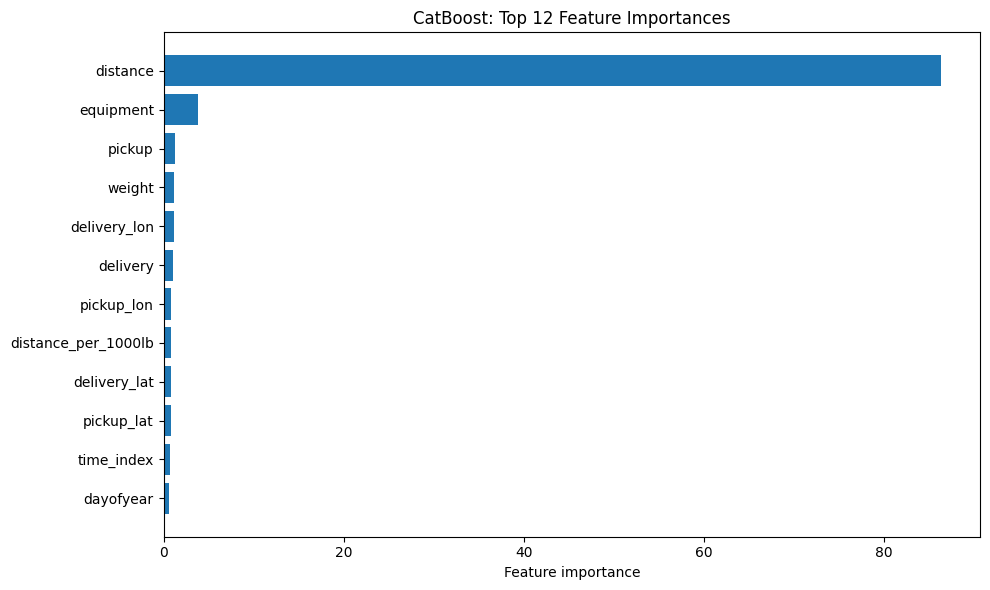

In [67]:

importance_df = pd.DataFrame({
    "Feature": catboost_model.feature_names_,
    "Importance": catboost_model.get_feature_importance()
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))
top_features = importance_df.head(12).sort_values("Importance")

plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature importance")
plt.title("CatBoost: Top 12 Feature Importances")
plt.tight_layout()
plt.show()

Prepare Full Dataset

In [68]:

X_full = make_features(
    train.drop(columns=["posted_rate"])
)

y_full = train["posted_rate"].copy()

# Match categorical representation used by CatBoost
for col in categorical_features:
    X_full[col] = X_full[col].fillna("MISSING").astype(str)

print("Full training features:", X_full.shape)
print("Full training target:", y_full.shape)

Full training features: (48000, 17)
Full training target: (48000,)


Train final catboost

In [69]:
from catboost import CatBoostRegressor

final_model = CatBoostRegressor(
    iterations=354,
    depth=8,
    learning_rate=0.04,
    loss_function="MAE",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

final_model.fit(
    X_full,
    y_full,
    cat_features=categorical_features
)

print("Final model training complete.")

0:	learn: 1088.7011359	total: 91.9ms	remaining: 32.5s
100:	learn: 121.9318996	total: 9.02s	remaining: 22.6s
200:	learn: 95.7794466	total: 17.9s	remaining: 13.7s
300:	learn: 90.8077339	total: 25.4s	remaining: 4.48s
353:	learn: 89.0845928	total: 30.8s	remaining: 0us
Final model training complete.


Predict November

In [70]:
X_test = make_features(validation)

for col in categorical_features:
    X_test[col] = X_test[col].fillna("MISSING").astype(str)

# Align feature order with the final training data
X_test = X_test[X_full.columns]

november_predictions = final_model.predict(X_test)

# Basic safety checks
assert len(november_predictions) == 12000
assert np.isfinite(november_predictions).all()

print("Predictions generated:", len(november_predictions))
print("Minimum prediction:", november_predictions.min())
print("Maximum prediction:", november_predictions.max())

Predictions generated: 12000
Minimum prediction: 205.8442934188961
Maximum prediction: 6705.6552377463395


Create submission file

In [71]:
submission = pd.DataFrame({
    "load_id": validation["load_id"],
    "predicted_rate": november_predictions
})

assert submission.columns.tolist() == [
    "load_id",
    "predicted_rate"
]
assert len(submission) == 12000
assert submission["load_id"].is_unique
assert submission["predicted_rate"].notna().all()

submission.to_csv(
    "/content/validation_predictions.csv",
    index=False
)

print("Submission saved successfully.")
display(submission.head())

Submission saved successfully.


,load_id,predicted_rate
0,TE-000001,854.165347
1,TE-000002,5078.513129
2,TE-000003,5153.727120
3,TE-000004,4030.403652
4,TE-000005,1877.503172


verify the complete CSV

In [72]:

import os

output_path = "/content/validation_predictions.csv"
preds = pd.read_csv(output_path)

print("File exists:", os.path.exists(output_path))
print("Rows:", len(preds))
print("Columns:", preds.columns.tolist())
print("Unique load IDs:", preds["load_id"].nunique())
print("Missing values:\n", preds.isna().sum())
print("All predictions finite:", np.isfinite(preds["predicted_rate"]).all())
print("\nSummary statistics:")
print(preds["predicted_rate"].describe())

assert len(preds) == 12000, "Expected 12,000 predictions"
assert preds.columns.tolist() == ["load_id", "predicted_rate"]
assert preds["load_id"].nunique() == 12000
assert preds["predicted_rate"].notna().all()
assert np.isfinite(preds["predicted_rate"]).all()

print("\nAll validation prediction checks passed.")

File exists: True
Rows: 12000
Columns: ['load_id', 'predicted_rate']
Unique load IDs: 12000
Missing values:
 load_id           0
predicted_rate    0
dtype: int64
All predictions finite: True

Summary statistics:
count    12000.000000
mean      2372.061444
std       1364.275621
min        205.844293
25%       1278.069449
50%       2044.534292
75%       3381.435777
max       6705.655238
Name: predicted_rate, dtype: float64

All validation prediction checks passed.


In [73]:

print("Available dataset variables:")
for name in ["train", "train_df", "validation", "december_inputs",
             "december_df", "december", "X_full", "catboost_model"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}",
              f"shape={obj.shape}" if hasattr(obj, "shape") else "")

print("\nDecember input preview:")

Available dataset variables:
train: DataFrame shape=(48000, 14)
validation: DataFrame shape=(12000, 13)
december: DataFrame shape=(31, 7)
X_full: DataFrame shape=(48000, 17)
catboost_model: CatBoostRegressor 

December input preview:


In [74]:

# Cell 27 (corrected): Generate December predictions

import pandas as pd
import numpy as np

# 1. Preserve the original December input and its required columns.
december_output = december.copy()
december_work = december.copy()

# 2. Build city-coordinate lookup tables from the training data.
pickup_coords = (
    train.groupby("pickup")[["pickup_lat", "pickup_lon"]]
    .mean()
)

delivery_coords = (
    train.groupby("delivery")[["delivery_lat", "delivery_lon"]]
    .mean()
)

# 3. Add coordinates to a temporary copy only.
december_work["pickup_lat"] = (
    december_work["pickup"].map(pickup_coords["pickup_lat"])
)
december_work["pickup_lon"] = (
    december_work["pickup"].map(pickup_coords["pickup_lon"])
)
december_work["delivery_lat"] = (
    december_work["delivery"].map(delivery_coords["delivery_lat"])
)
december_work["delivery_lon"] = (
    december_work["delivery"].map(delivery_coords["delivery_lon"])
)

# Use training-data coordinate averages if a city is unseen.
for col in ["pickup_lat", "pickup_lon",
            "delivery_lat", "delivery_lon"]:
    december_work[col] = december_work[col].fillna(train[col].mean())

# 4. Create the same features used by the trained model.
december_features = make_features(december_work)

# Match the final training feature columns and their order.
december_features = december_features.reindex(
    columns=X_full.columns
)

# 5. Handle categorical and numeric values consistently.
for col in categorical_features:
    if col in december_features.columns:
        december_features[col] = (
            december_features[col]
            .fillna("MISSING")
            .astype(str)
        )

for col in december_features.columns:
    if col not in categorical_features:
        december_features[col] = pd.to_numeric(
            december_features[col], errors="coerce"
        )
        december_features[col] = december_features[col].fillna(
            X_full[col].median()
        )

# 6. Generate predictions for all 31 December dates.
december_rates = catboost_model.predict(december_features)

assert len(december_rates) == 31, "Expected 31 December predictions"
assert np.isfinite(december_rates).all(), "Invalid prediction values"

# 7. Add predictions to the original dataset, not the temporary copy.
december_output["predicted_rate"] = december_rates

# Keep the original seven columns and their order.
expected_columns = [
    "pickup", "delivery", "distance", "equipment",
    "weight", "date", "predicted_rate"
]

assert december_output.columns.tolist() == expected_columns, (
    f"Unexpected columns: {december_output.columns.tolist()}"
)
assert december_output["predicted_rate"].notna().all()
assert (december_output["predicted_rate"] > 0).all()

# Update the notebook variable and save the completed CSV.
december = december_output.copy()
december.to_csv("/content/december_chart_inputs.csv", index=False)

print("December predictions generated successfully.")
print("Rows:", len(december))
print("Columns:", december.columns.tolist())
print("Prediction range: $"
      + f"{december['predicted_rate'].min():,.2f}"
      + " to $"
      + f"{december['predicted_rate'].max():,.2f}")

display(december.head())

December predictions generated successfully.
Rows: 31
Columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']
Prediction range: $806.07 to $838.03


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,814.378750
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,821.618264
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,831.142489
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,831.015646
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,828.404118


Scorer found: /content/score.py

--- SCORER OUTPUT ---
Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: /content/scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


Scorer completed. December chart: /content/scorer_results/candidate_december.png


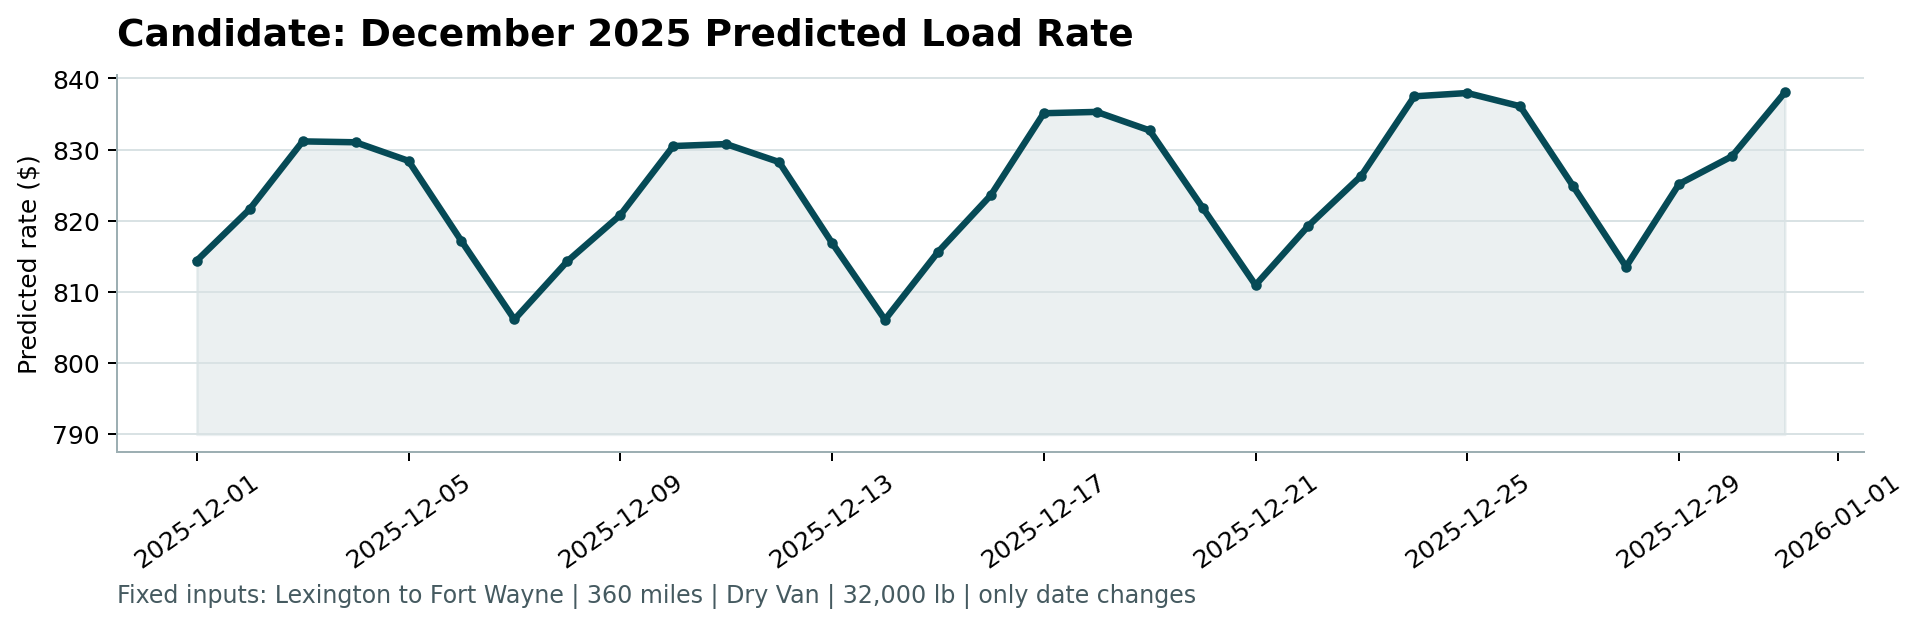

In [75]:

from pathlib import Path
import shutil
import subprocess
import sys

# Assessment files are already in /content
assessment_dir = Path("/content")
data_dir = assessment_dir / "data"
data_dir.mkdir(exist_ok=True)

# Locate score.py
score_files = list(assessment_dir.rglob("score.py"))
if not score_files:
    raise FileNotFoundError(
        "Cannot find score.py. Check that you uploaded and extracted the assessment ZIP."
    )

score_script = score_files[0]
print("Scorer found:", score_script)

# Check validation predictions
validation_file = assessment_dir / "validation_predictions.csv"
if not validation_file.exists():
    raise FileNotFoundError("validation_predictions.csv is missing.")

# Copy December predictions only if they are not already at the destination
december_source = assessment_dir / "december_chart_inputs.csv"
december_destination = data_dir / "december_chart_inputs.csv"

if not december_source.exists():
    raise FileNotFoundError(
        "december_chart_inputs.csv is missing from /content."
    )

if december_source.resolve() != december_destination.resolve():
    shutil.copy2(december_source, december_destination)

# Run the official scorer
output_dir = assessment_dir / "scorer_results"

result = subprocess.run(
    [
        sys.executable,
        str(score_script),
        "--predictions", str(validation_file),
        "--december-predictions", str(december_destination),
        "--output-dir", str(output_dir),
    ],
    capture_output=True,
    text=True,
)

print("\n--- SCORER OUTPUT ---")
print(result.stdout)

if result.stderr:
    print("\n--- ERROR DETAILS ---")
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError(
        f"The scorer failed with exit code {result.returncode}. "
        "Review the output above."
    )

chart_path = output_dir / "candidate_december.png"
if chart_path.exists():
    print("\nScorer completed. December chart:", chart_path)

    from IPython.display import display, Image
    display(Image(filename=str(chart_path)))
else:
    print("\nScorer returned successfully, but the expected chart was not found.")

In [77]:
# Confirm prediction CSV structure
validation = pd.read_csv(base / "validation_predictions.csv")
december = pd.read_csv(base / "data" / "december_chart_inputs.csv")

print("\nValidation shape:", validation.shape)
print("Validation columns:", validation.columns.tolist())
print("December shape:", december.shape)
print("December columns:", december.columns.tolist())


Validation shape: (12000, 2)
Validation columns: ['load_id', 'predicted_rate']
December shape: (31, 7)
December columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']
